In [12]:
# Primeiros passos:

# Importar biblioteca
import pandas as pd

# Carregar dataset
df = pd.read_csv("bank-full.csv", sep=";")

# Mostrar
print("Shape:",df.shape)
print(display(df.head())) # print-display é pra facilitar a cópia das saídas no VSCode

Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


None


O que cada coluna representa?

| Variável    | Descrição                                        | Tipo       |
| ----------- | ------------------------------------------------ | ---------- |
| `age`       | Idade do cliente                                 | Numérica   |
| `job`       | Ocupação                                         | Categórica |
| `marital`   | Estado civil                                     | Categórica |
| `education` | Escolaridade                                     | Categórica |
| `default`   | Possui crédito em inadimplência?                 | Categórica |
| `balance`   | Saldo médio anual                                | Numérica   |
| `housing`   | Possui empréstimo imobiliário?                   | Categórica |
| `loan`      | Possui empréstimo pessoal?                       | Categórica |
| `contact`   | Tipo de comunicação utilizada                    | Categórica |
| `day`       | Dia do último contato                            | Numérica   |
| `month`     | Mês do último contato                            | Categórica |
| `duration`  | Duração do último contato, em segundos           | Numérica   |
| `campaign`  | Número de contatos nesta campanha                | Numérica   |
| `pdays`     | Dias desde o último contato em campanha anterior | Numérica   |
| `previous`  | Número de contatos em campanhas anteriores       | Numérica   |
| `poutcome`  | Resultado da campanha anterior                   | Categórica |
| `y`         | O cliente aderiu ao depósito a prazo?            | Alvo       |

### O que estamos tentando prever?
A variável-alvo y indica se o cliente aderiu ou não a um depósito a prazo oferecido pelo banco.

Um depósito a prazo é um produto financeiro no qual o cliente deposita uma quantia no banco por determinado período, normalmente com uma remuneração (juros) previamente estabelecida ou definida por condições contratuais.

É semelhante, em termos gerais, a um CDB no Brasil: o cliente deixa o dinheiro aplicado por um prazo e recebe uma remuneração conforme as condições do produto.

Portanto:
- y = yes: o cliente aceitou a oferta e aderiu ao depósito a prazo.
- y = no: o cliente não aderiu.

In [28]:
# Primeira inspeção dos dados

print("----------------------------------------------------------------------------------------------------------------------------")
print("Info:\n")
df.info()

print("----------------------------------------------------------------------------------------------------------------------------")
print("Describe:\n")
display(df.describe(include="all").T)

print("----------------------------------------------------------------------------------------------------------------------------")
print("Valores ausentes:\n")
print(df.isna().sum())

print("----------------------------------------------------------------------------------------------------------------------------")
print("Distribuição da variável-alvo:\n")
print(df["y"].value_counts(normalize=True) * 100)

----------------------------------------------------------------------------------------------------------------------------
Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


----------------------------------------------------------------------------------------------------------------------------
Valores ausentes:

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
----------------------------------------------------------------------------------------------------------------------------
Distribuição da variável-alvo:

no     88.30152
yes    11.69848
Name: y, dtype: float64


In [41]:
# Relevante: 'unknown' aparece em 36959 dos 45211 dados (82%) em poutcome!

# Isso pode ser problemático porque algo desconhecido não releva padrão nenhum. Pode ser tanto algo bom quanto algo ruim
# Uma das possibilidades de lidar com isso seria excluir dados que contenham essa particularidade.
# Porém, se considerássemos excluir todas as linhas que apresentam pelo menos um unknown, já sabemos 
# que a coluna poutcome nos faria perder 82% do dataset.
# Entáo, talvez seja preciso eliminar essa coluna problemática... Mas antes, vamos ver se essa é uma particularidade dela
# ou se isso também acontece em outras colunas

In [42]:
# Vamos fazer uma inspeção de categorias desconhecidas (unknown)

# Selecionar as variáveis categóricas, excluindo a poutcome, cuja alta quantidade de unknown já foi identificada
categorical_cols = df.select_dtypes(include="object").columns.drop(["poutcome"])
# Desconsiderar dessa contagem porque já sabemos que 82% dela é unknown. Queremos o padrão no restante do dataset

# Contar os valores unknown individualmente em cada variável
unknown_counts = (df[categorical_cols] == "unknown").sum()

# Organizar as quantidades e os respectivos percentuais
unknown_summary = pd.DataFrame({
    "Quantidade": unknown_counts,
    "Percentual (%)": unknown_counts / len(df) * 100
}).sort_values("Quantidade", ascending=False)

print("Distribuição de categorias desconhecidas por variável:\n")
display(unknown_summary)

# Verificar se cada registro possui pelo menos um unknown nas variáveis selecionadas
unknown_rows = (df[categorical_cols] == "unknown").any(axis=1) 
# any(axis=1)  verifica se existe pelo menos um True na linha. 
# O axis=1 indica que a verificação acontece horizontalmente, entre as colunas.

# Contar os registros com pelo menos um unknown.
print(f"\nRegistros com pelo menos um unknown: {unknown_rows.sum()}")

# Calcular o percentual desses registros no dataset.
print(f"Percentual: {unknown_rows.mean() * 100:.2f}%")

# Identificar os registros sem nenhum unknown
complete_rows = ~unknown_rows # inverte os valores booleanos (True vira False e vice-versa)

# Contar os registros sem categorias desconhecidas
print(f"\nRegistros sem nenhum unknown: {complete_rows.sum()}")

# Calcular o percentual de registros sem unknown
print(f"Percentual: {complete_rows.mean() * 100:.2f}%")

Distribuição de categorias desconhecidas por variável:



,Quantidade,Percentual (%)
contact,13020,28.798301
education,1857,4.107407
job,288,0.637013
marital,0,0.000000
default,0,0.000000
housing,0,0.000000
loan,0,0.000000
month,0,0.000000
y,0,0.000000



Registros com pelo menos um unknown: 14304
Percentual: 31.64%

Registros sem nenhum unknown: 30907
Percentual: 68.36%


In [43]:
# Então, agora sabemos que apenas poutcome, contact, education e job têm valores desconhecidos.
# Para decidirmos o que fazer com essas colunas, vamos analisar se elas têm relações peculiares com a variável-alvo.

In [48]:

# Análise da taxa de adesão por categoria desconhecida

#---------------------------------------------------------------------------------------------------------------------------------
# Mas, antes de qualquer coisa, devemos levar em consideração que a proporção entre as classes 0 e 1 já é muito desbalanceada:
#   Não aderiu:  88,30%
#   Aderiu:      11,70%
# Então, temos que usar essa referência para interpretar todas as tabelas de distribuição por categoria.
# Sendo assim, vamos calcular a diferença em pontos percentuais em relação à taxa geral de adesão:

#                                Diferença percentual = Taxa da categoria - taxa geral

# Portanto:
# - Resultado positivo: adesão acima da média geral.
# - Resultado negativo: adesão abaixo da média geral.
# - Resultado próximo de zero: comportamento próximo à distribuição original.

# Vamos usar também o conceito de "lift", que representa quantas vezes a taxa daquela categoria corresponde à taxa geral:

#                                        Lift = Taxa da categoria / Taxa geral

# Um lift de 1,5 significa uma taxa de adesão 50% superior à média geral.
#---------------------------------------------------------------------------------------------------------------------------------

# Agora sim, vamos fazer a análise da taxa de adesão por categoria,
# considerando o desbalanceamento original da variável-alvo.


# Calcular a taxa geral de adesão no dataset.
# O resultado de mean() representa a proporção de valores "yes"
baseline = (df["y"] == "yes").mean() * 100
print(f"Taxa geral de adesão: {baseline:.2f}%")

# Analisar cada coluna que tem unknown
for col in ["poutcome", "contact", "education", "job"]:

    # Separadores estéticos
    print(f"\n{'-' * 75}")
    print(f"Variável: {col}")
    print(f"{'-' * 75}")

    # Agrupar os registros por categoria e calcular
    # a quantidade de clientes e a quantidade de adesões.
    summary = df.groupby(col)["y"].agg(
        Total="count",
        Adesoes=lambda x: (x == "yes").sum()
    )

    # Calcular a taxa de adesão de cada categoria.
    summary["Adesao (%)"] = (
        summary["Adesoes"] / summary["Total"] * 100
    )

    # Calcular a diferença em pontos percentuais
    # em relação à taxa geral de adesão.
    summary["Diferenca (p.p.)"] = (
        summary["Adesao (%)"] - baseline
    )

    # Calcular o lift (quantas vezes a taxa da categoria
    # representa a taxa geral de adesão).
    summary["Lift"] = (
        summary["Adesao (%)"] / baseline
    )

    # Ordenar as categorias pela taxa de adesão.
    summary = summary.sort_values(
        "Adesao (%)", ascending=False
    )

    print(display(summary.round(2)))


Taxa geral de adesão: 11.70%

---------------------------------------------------------------------------
Variável: poutcome
---------------------------------------------------------------------------


,Total,Adesoes,Adesao (%),Diferenca (p.p.),Lift
poutcome,,,,,
success,1511,978,64.73,53.03,5.53
other,1840,307,16.68,4.99,1.43
failure,4901,618,12.61,0.91,1.08
unknown,36959,3386,9.16,-2.54,0.78


None

---------------------------------------------------------------------------
Variável: contact
---------------------------------------------------------------------------


,Total,Adesoes,Adesao (%),Diferenca (p.p.),Lift
contact,,,,,
cellular,29285,4369,14.92,3.22,1.28
telephone,2906,390,13.42,1.72,1.15
unknown,13020,530,4.07,-7.63,0.35


None

---------------------------------------------------------------------------
Variável: education
---------------------------------------------------------------------------


,Total,Adesoes,Adesao (%),Diferenca (p.p.),Lift
education,,,,,
tertiary,13301,1996,15.01,3.31,1.28
unknown,1857,252,13.57,1.87,1.16
secondary,23202,2450,10.56,-1.14,0.90
primary,6851,591,8.63,-3.07,0.74


None

---------------------------------------------------------------------------
Variável: job
---------------------------------------------------------------------------


,Total,Adesoes,Adesao (%),Diferenca (p.p.),Lift
job,,,,,
student,938,269,28.68,16.98,2.45
retired,2264,516,22.79,11.09,1.95
unemployed,1303,202,15.50,3.80,1.33
management,9458,1301,13.76,2.06,1.18
admin.,5171,631,12.20,0.50,1.04
self-employed,1579,187,11.84,0.14,1.01
unknown,288,34,11.81,0.11,1.01
technician,7597,840,11.06,-0.64,0.95
services,4154,369,8.88,-2.82,0.76


None


A comparação entre as taxas de adesão, as diferenças em pontos percentuais e os valores de lift permitiu identificar diferentes padrões entre as categorias desconhecidas. Enquanto `contact = unknown` apresenta uma taxa de adesão consideravelmente inferior à média geral (lift = 0,35), as categorias desconhecidas de `education` e `job` apresentam valores próximos à referência (lifts de 1,16 e 1,01, respectivamente).

Em `poutcome`, embora `unknown` também apresente lift abaixo de 1 (0,78), a variável contém a categoria `success`, cujo lift de 5,53 indica uma associação expressiva com a adesão.

Diante desses resultados, optamos por **manter as quatro variáveis e suas categorias desconhecidas**, preservando possíveis padrões associados à adesão e evitando a exclusão prematura de informações que poderão contribuir para a modelagem.

In [50]:
# Agora vamos analisar as variáveis pdays e previous
# (se as duas variáveis estão registrando essencialmente a mesma situação para esses clientes)

# A documentação do dataset define pdays = -1 como ausência de contato em campanhas anteriores. 
# Já 0 seria uma distância de zero dias, mas não aparece nos registros.

print("Clientes sem contatos anteriores (previous = 0):")
print((df["previous"] == 0).sum())

print("\nClientes sem contato anterior identificado (pdays = -1):")
print((df["pdays"] == -1).sum())

# Verifica se as duas condições identificam exatamente os mesmos registros.
print("\nRegistros que atendem simultaneamente às duas condições:")
print(((df["previous"] == 0) & (df["pdays"] == -1)).sum())

# Verifica se existem registros em que apenas uma das condições é verdadeira.
print("\nRegistros com condições divergentes:")
print(((df["previous"] == 0) != (df["pdays"] == -1)).sum())

#---

# Verificação dos valores especiais de pdays
print("\nDistribuição de pdays:")
print(df["pdays"].value_counts().sort_index().head(15))

print("\nRegistros com pdays = -1:")
print((df["pdays"] == -1).sum())

print("\nRegistros com pdays = 0:")
print((df["pdays"] == 0).sum())

Clientes sem contatos anteriores (previous = 0):
36954

Clientes sem contato anterior identificado (pdays = -1):
36954

Registros que atendem simultaneamente às duas condições:
36954

Registros com condições divergentes:
0

Distribuição de pdays:
-1     36954
 1        15
 2        37
 3         1
 4         2
 5        11
 6        10
 7         7
 8        25
 9        12
 10        6
 12        7
 13        6
 14        9
 15        3
Name: pdays, dtype: int64

Registros com pdays = -1:
36954

Registros com pdays = 0:
0


In [ ]:
# Isso demonstra que, neste dataset, as duas condições identificam exatamente os mesmos registros.
# Porém,
# embora as duas variáveis carreguem uma informação parcialmente redundante, elas não são completamente equivalentes.
# Para os clientes que já foram contatados anteriormente, previous informa quantos contatos ocorreram, 
# enquanto pdays informa há quantos dias ocorreu o último contato.

In [53]:
''' Variável durantion'''
# A variável duration representa a duração da última ligação, em segundos.
# Como essa informação só está disponível após a realização do contato,
# ela não poderá ser utilizada em uma previsão feita antes da ligação.

# Portanto, duration será excluída das variáveis preditoras.

# Observação:
# Essa decisão sobre duration pressupõe que queremos prever a adesão ANTES da ligação. 
# Se o objetivo fosse prever durante ou depois da conversa, o cenário seria outro. 

' Variável durantion'

In [ ]:
# Agora vamos analisar como as variáveis numéricas se relacionam resultado da campanha

# Selecionar as variáveis numéricas, excluindo duration,
# que não estará disponível no momento da previsão
numeric_cols = [
    "age", "balance", "day",
    "campaign", "pdays", "previous"
]

# Calcular estatísticas descritivas separadamente
# para clientes que aderiram e não aderiram
summary = df.groupby("y")[numeric_cols].describe().T

print(display(summary.round(2)))

y                      no       yes
age      count   39922.00   5289.00
         mean       40.84     41.67
         std        10.17     13.50
         min        18.00     18.00
         25%        33.00     31.00
         50%        39.00     38.00
         75%        48.00     50.00
         max        95.00     95.00
balance  count   39922.00   5289.00
         mean     1303.71   1804.27
         std      2974.20   3501.10
         min     -8019.00  -3058.00
         25%        58.00    210.00
         50%       417.00    733.00
         75%      1345.00   2159.00
         max    102127.00  81204.00
day      count   39922.00   5289.00
         mean       15.89     15.16
         std         8.29      8.50
         min         1.00      1.00
         25%         8.00      8.00
         50%        16.00     15.00
         75%        21.00     22.00
         max        31.00     31.00
campaign count   39922.00   5289.00
         mean        2.85      2.14
         std         3.21      1.92
         min         1.00      1.00
         25%         1.00      1.00
         50%         2.00      2.00
         75%         3.00      3.00
         max        63.00     32.00
pdays    count   39922.00   5289.00
         mean       36.42     68.70
         std        96.76    118.82
         min        -1.00     -1.00
         25%        -1.00     -1.00
         50%        -1.00     -1.00
         75%        -1.00     98.00
         max       871.00    854.00
previous count   39922.00   5289.00
         mean        0.50      1.17
         std         2.26      2.55
         min         0.00      0.00
         25%         0.00      0.00
         50%         0.00      0.00
         75%         0.00      1.00
         max       275.00     58.00

None


Observações feitas a partir desses dados:
- age: as medianas são próximas (38 e 39 anos), mas o grupo que aderiu apresenta maior dispersão.
- balance: quem aderiu apresenta saldo mediano maior (733 contra 417), embora os dois grupos tenham valores bastante dispersos.
- day: nenhuma informação relevante, pois obviamente os dados estão separados em valores de 1 a 31.
- campaign: quem aderiu recebeu menos contatos na campanha atual, em mediana (2 contra 2, mas a média é 2,14 contra 2,85).
- pdays: o terceiro quartil é bastante diferente (98 para quem aderiu e -1 para quem não aderiu), sugerindo uma diferença interessante no histórico de contatos anteriores.
- previous: a média também é maior entre quem aderiu (1,17 contra 0,50).

Possíveis outliers que chamaram atenção:
- previous: Q3 (o 75%) = 0, mas há registros com 275 contatos anteriores.
- campaign: Q3 (o 75%) = 3, mas há registros com até 63 contatos na campanha atual.
- pdays: há valores de até 871 dias, enquanto pelo menos 75% dos registros do grupo que não aderiu apresentam valor -1.

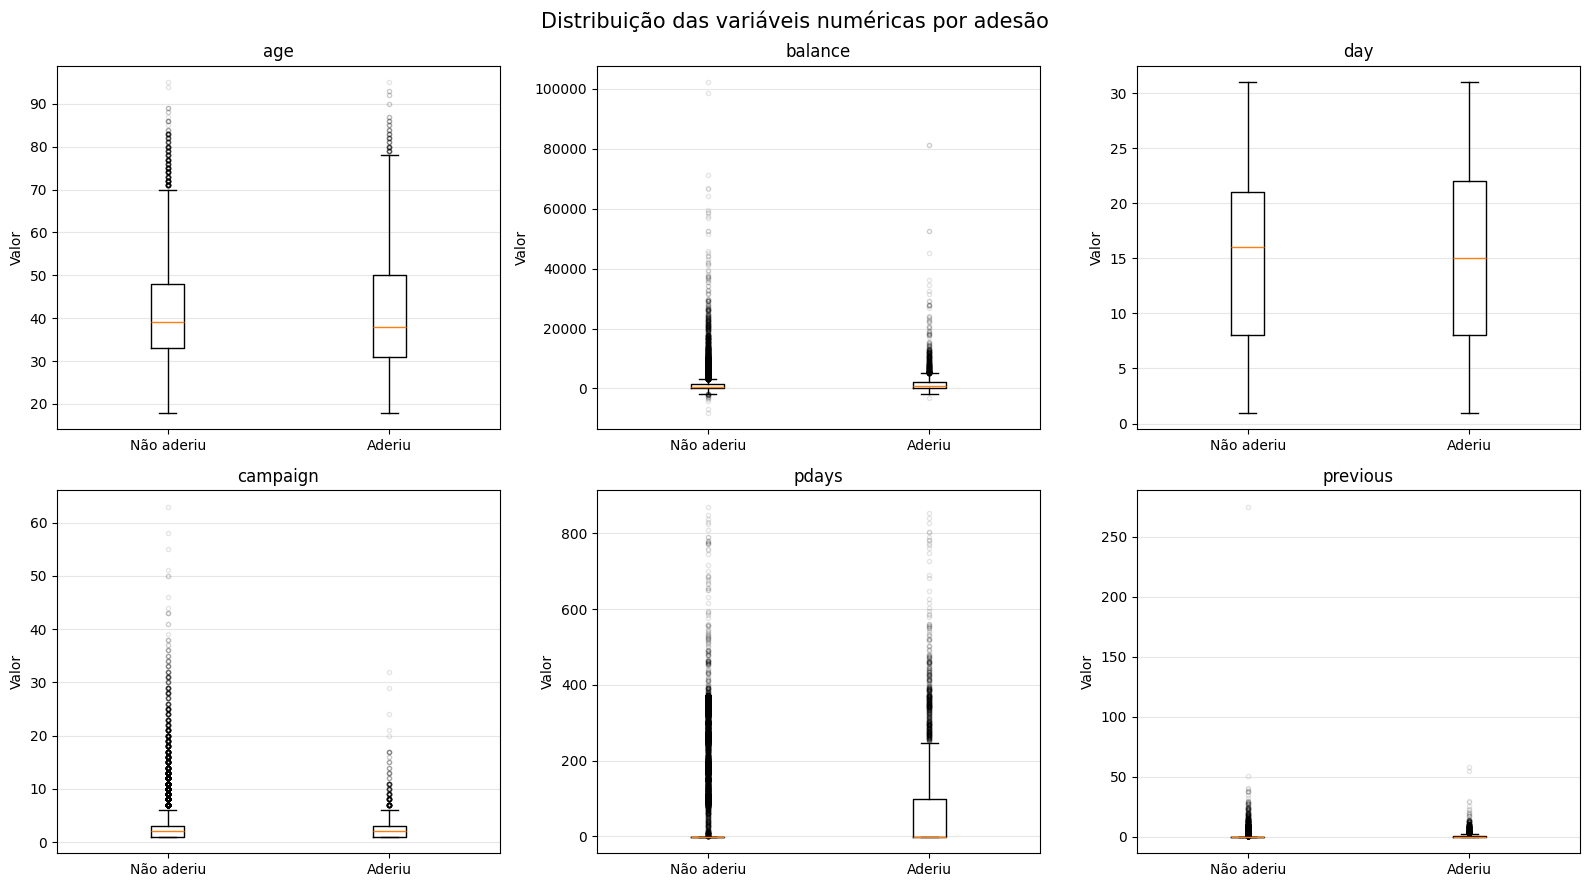

In [ ]:
# Agora vamos usar boxplots para visualização gráfica, pois eles permitem comparar medianas, 
# dispersões e valores extremos entre os dois grupos. É uma boa primeira visualização para essa etapa.

import matplotlib.pyplot as plt

# Variáveis numéricas que serão comparadas.
numeric_cols = [
    "age", "balance", "day",
    "campaign", "pdays", "previous"
]

# Criar uma grade de gráficos com 2 linhas e 3 colunas
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Comparar a distribuição de cada variável entre os grupos
for col, ax in zip(numeric_cols, axes.flatten()):

    # Separar os valores de acordo com o resultado da campanha
    data = [
        df.loc[df["y"] == "no", col],
        df.loc[df["y"] == "yes", col]
    ]

    # Construir o boxplot.
    ax.boxplot(
        data,
        labels=["Não aderiu", "Aderiu"], # Em outras versões do matplotlib, esse parâmetro pode se chamar tick_labels
        showfliers=True, # Mostrar dados fora dos bigodes do gráfico
        flierprops=dict(
                            marker="o",
                            markersize=3,
                            alpha=0.1 # opacidade dos marcadores (o baixo valor facilita a identificação de zonas com maior densidade)
                        )
    )

    ax.set_title(col)
    ax.set_ylabel("Valor")
    ax.grid(axis="y", alpha=0.3)

# Ajustar o espaçamento entre os gráficos
plt.suptitle(
    "Distribuição das variáveis numéricas por adesão",
    fontsize=15
)

plt.tight_layout()
plt.show()


Observa-se a presença de valores extremos em todas as variáveis numéricas, exceto `day`, como esperado pela natureza dessa variável. Algumas distribuições apresentam concentrações expressivas de observações além dos limites dos boxplots, indicando assimetria e dispersão dos dados. Essas características serão consideradas na etapa de pré-processamento, especialmente na escolha das técnicas de escalonamento, evitando a remoção automática de observações que podem representar comportamentos legítimos dos clientes.

In [ ]:
# O próximo passo é analisar a relação entre as variáveis categóricas e a variável-alvo y.

# A ideia é investigar se determinadas categorias apresentam taxas de adesão (yes) diferentes. 
# Isso pode revelar associações interessantes e ajudar a identificar variáveis potencialmente relevantes para a classificação.

In [ ]:
# continua...